In [1]:
# Quantum Kernel SVM for Credit Card Fraud Detection

In [2]:
## 1. Setup
!pip install qiskit  qiskit_machine_learning  pylatexenc

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import recall_score, precision_score, average_precision_score
from sklearn.linear_model import LogisticRegression
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from sklearn.metrics import PrecisionRecallDisplay

In [5]:
## 2. Data
X,y=fetch_openml(data_id=1597, as_frame=True, return_X_y=True)
print(X.shape, X.columns, y.unique(), y.dtype)
print(y.value_counts(normalize=True))

y=y.astype('int')
Fraud_samples=X[y==1]
Normal_samples=X[y==0]

(284807, 29) Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount'],
      dtype='object') ['0', '1']
Categories (2, object): ['0', '1'] category
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


In [6]:
fmap = zz_feature_map(feature_dimension=4, reps=2, entanglement='linear')
fmap.draw()

┌───┐┌───────────┐                                          ┌───┐»
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘»
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«            ┌───────────┐                                                    »
«0: ─────────┤ P(2*x[0]) ├────────────────────────────────────────────────────»
«            └───────────┘               ┌───┐         ┌───────────┐          »
«1: ──────────────────────────────────■──┤ H ├─────────┤ P(2*x[1]) ├──────────»
«   ┌──────────────────────────────┐┌─┴─┐└───┘         └───────────┘          »
«2: ┤ P((-π + x[1])*(-π + x[2])*2) ├┤ X ├──■──────────────────────────────────»
«   └──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐»
«3: ─────────────────────────────────────┤ X ├┤ P((-π + x[2])*(-π + x[3])*2) ├»
«                                        └───┘└──────────────────────────────┘»
«                                                          »
«0: ──■────────────────────────────────────────■───────────»
«   ┌─┴─┐┌──────────────────────────────┐    ┌─┴─┐         »
«1: ┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├────┤ X ├──────■──»
«   └───┘└────────────┬───┬─────────────┘┌───┴───┴───┐┌─┴─┐»
«2: ──■───────────────┤ H ├──────────────┤ P(2*x[2]) ├┤ X ├»
«   ┌─┴─┐             ├───┤              ├───────────┤└───┘»
«3: ┤ X ├─────────────┤ H ├──────────────┤ P(2*x[3]) ├─────»
«   └───┘             └───┘              └───────────┘     »
«                                                                             »
«0: ──────────────────────────────────────────────────────────────────────────»
«                                                                             »
«1: ──────────────────────────────────■───────────────────────────────────────»
«   ┌──────────────────────────────┐┌─┴─┐                                     »
«2: ┤ P((-π + x[1])*(-π + x[2])*2) ├┤ X ├──■──────────────────────────────────»
«   └──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐»
«3: ─────────────────────────────────────┤ X ├┤ P((-π + x[2])*(-π + x[3])*2) ├»
«                                        └───┘└──────────────────────────────┘»
«        
«0: ─────
«        
«1: ─────
«        
«2: ──■──
«   ┌─┴─┐
«3: ┤ X ├
«   └───┘

In [13]:
def quantum_kernel_fraud_detection(seed, n_components):

  Fraud=Fraud_samples.sample(n=100, random_state=seed)
  Normal=Normal_samples.sample(n=400, random_state=seed)
  X_sub=pd.concat([Fraud, Normal])
  y_sub=np.array([1]*100 + [0]*400)

  ## 3. Preprocessing
  train_x, test_x, train_y, test_y= train_test_split(X_sub,y_sub, test_size=0.3, stratify=y_sub, random_state=seed)
  scaler=StandardScaler()
  train_x=scaler.fit_transform(train_x)
  test_x=scaler.transform(test_x)

  pca=PCA(n_components)
  train_x=pca.fit_transform(train_x)
  test_x=pca.transform(test_x)
  n_qubits = n_components

  minmax=MinMaxScaler(feature_range=(0,np.pi))
  train_x=minmax.fit_transform(train_x)
  test_x=minmax.transform(test_x)

  ## 4. Classical baselines
  ## 4.1. Support Vector Classifier
  svc=SVC(kernel='rbf', class_weight='balanced')
  svc.fit(train_x, train_y)
  pred_svc=svc.predict(test_x)
  score_svc=svc.decision_function(test_x)

  ## 4.2. Logistic Regression
  lr=LogisticRegression(class_weight='balanced')
  lr.fit(train_x, train_y)
  pred_lr=lr.predict(test_x)
  score_lr=lr.decision_function(test_x)

  ## 5. Quantum kernel
  fmap=zz_feature_map(feature_dimension=n_qubits, reps=2, entanglement='linear')
  q_kernel=FidelityStatevectorKernel(feature_map=fmap)
  K_train=q_kernel.evaluate(x_vec=train_x)
  off_diag = K_train[np.triu_indices(len(K_train), k=1)]
  K_test=q_kernel.evaluate(x_vec=test_x,y_vec=train_x)

  qsvc=SVC(kernel='precomputed', class_weight='balanced')
  qsvc.fit(K_train, train_y)
  q_pred=qsvc.predict(K_test)
  q_score=qsvc.decision_function(K_test)

  ## 6. Results
  results= pd.DataFrame({
    'Model':['SVC (rbf)', 'Logistic Regression', 'Quantum SVC (ZZ)' ],
    'Recall':[recall_score(test_y, pred_svc), recall_score(test_y, pred_lr), recall_score(test_y, q_pred)],
    'Precision':[precision_score(test_y, pred_svc), precision_score(test_y, pred_lr), precision_score(test_y, q_pred)],
    'PR-AUC':[average_precision_score(test_y, score_svc), average_precision_score(test_y, score_lr), average_precision_score(test_y, q_score)],
    'seed': seed,
    'n_qubits': n_components,
    'kernel_offdiag_mean': off_diag.mean()
  })

  return results, test_y, score_svc, score_lr, q_score

                 Model  Recall  Precision  PR-AUC  seed  n_qubits  \
0            SVC (rbf)   0.867      0.963   0.930    42         4   
1  Logistic Regression   0.867      0.963   0.935    42         4   
2     Quantum SVC (ZZ)   0.867      0.963   0.956    42         4   

   kernel_offdiag_mean  
0                 0.61  
1                 0.61  
2                 0.61  


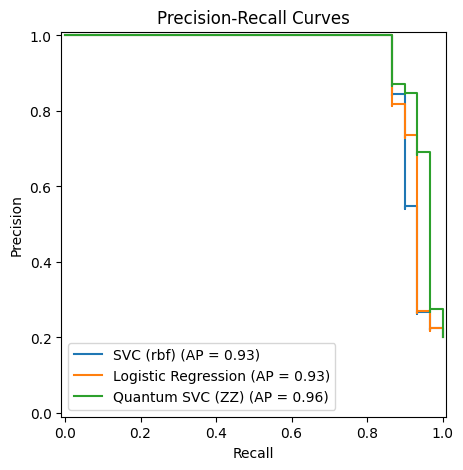

In [14]:
n_components = 4
seed = 42
results, test_y, score_svc, score_lr, q_score = quantum_kernel_fraud_detection(seed=seed, n_components=n_components)
print(results.round(3))
fig, ax= plt.subplots(figsize=(6,5))
PrecisionRecallDisplay.from_predictions(test_y, score_svc, name='SVC (rbf)', ax=ax)
PrecisionRecallDisplay.from_predictions(test_y, score_lr, name='Logistic Regression', ax=ax)
PrecisionRecallDisplay.from_predictions(test_y, q_score, name='Quantum SVC (ZZ)', ax=ax)
ax.set_title('Precision-Recall Curves')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
plt.savefig(f'pr_curves_{n_components}q_{seed}.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
all_results=[]
for n in [2,4,6,8,10]:
  for s in [0,1,2,3,4]:
    results,test_y, _, _, _=quantum_kernel_fraud_detection(seed=s, n_components=n)
    all_results.append(results)
    print(f'done: {n} qubits  seed {s}')

all_results=pd.concat(all_results, ignore_index=True)
all_results.to_csv('quantum_kernel_results.csv', index=False)



done: 2 qubits  seed 0
done: 2 qubits  seed 1
done: 2 qubits  seed 2
done: 2 qubits  seed 3
done: 2 qubits  seed 4
done: 4 qubits  seed 0
done: 4 qubits  seed 1
done: 4 qubits  seed 2
done: 4 qubits  seed 3
done: 4 qubits  seed 4
done: 6 qubits  seed 0
done: 6 qubits  seed 1
done: 6 qubits  seed 2
done: 6 qubits  seed 3
done: 6 qubits  seed 4
done: 8 qubits  seed 0
done: 8 qubits  seed 1
done: 8 qubits  seed 2
done: 8 qubits  seed 3
done: 8 qubits  seed 4
done: 10 qubits  seed 0
done: 10 qubits  seed 1
done: 10 qubits  seed 2
done: 10 qubits  seed 3
done: 10 qubits  seed 4


                  Model  n_qubits   mean    std
0   Logistic Regression         2  0.926  0.039
1   Logistic Regression         4  0.935  0.032
2   Logistic Regression         6  0.942  0.024
3   Logistic Regression         8  0.939  0.020
4   Logistic Regression        10  0.950  0.019
5      Quantum SVC (ZZ)         2  0.909  0.038
6      Quantum SVC (ZZ)         4  0.915  0.042
7      Quantum SVC (ZZ)         6  0.926  0.040
8      Quantum SVC (ZZ)         8  0.894  0.037
9      Quantum SVC (ZZ)        10  0.859  0.062
10            SVC (rbf)         2  0.926  0.038
11            SVC (rbf)         4  0.947  0.029
12            SVC (rbf)         6  0.957  0.012
13            SVC (rbf)         8  0.960  0.011
14            SVC (rbf)        10  0.960  0.019


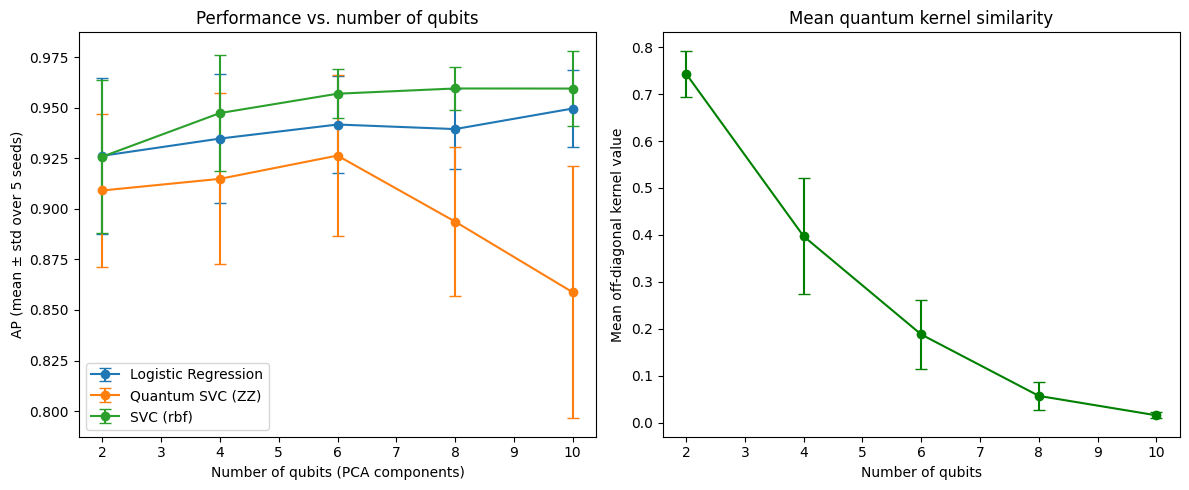

In [16]:
summary=all_results.groupby(['Model', 'n_qubits'])['PR-AUC'].agg(['mean', 'std']).reset_index()
print(summary.round(3))

fig,axes=plt.subplots(1,2,figsize=(12,5))
for model in summary['Model'].unique():
  d=summary[summary['Model']==model]
  axes[0].errorbar(d['n_qubits'], d['mean'], yerr=d['std'], marker='o', capsize=4, label=model)

axes[0].set_xlabel('Number of qubits (PCA components)')
axes[0].set_ylabel('AP (mean ± std over 5 seeds)')
axes[0].set_title('Performance vs. number of qubits')
axes[0].legend()

conc = (all_results[all_results['Model'] == 'Quantum SVC (ZZ)'].groupby('n_qubits')['kernel_offdiag_mean'].agg(['mean', 'std']).reset_index())
axes[1].errorbar(conc['n_qubits'], conc['mean'], yerr=conc['std'], marker='o', capsize=4, color='green')
axes[1].set_xlabel('Number of qubits')
axes[1].set_ylabel('Mean off-diagonal kernel value')
axes[1].set_title('Mean quantum kernel similarity')

plt.tight_layout()
plt.savefig('quantum_kernel_results.png', dpi=150, bbox_inches='tight')
plt.show()